In [ ]:

import json
import pandas as pd
from google.colab import files

# Cargar el archivo JSON
uploaded = files.upload()
nombre_archivo = next(iter(uploaded))

with open(nombre_archivo, "r", encoding="utf-8") as archivo:
    corpus = json.load(archivo)

# Crear tabla de datos
df = pd.DataFrame(corpus["registros"])

# Preparar las columnas para BERT
df_modelo = df[["texto_original", "categoria"]].copy()
df_modelo = df_modelo.rename(columns={
    "texto_original": "texto",
    "categoria": "etiqueta"
})

# Eliminar posibles filas incompletas
df_modelo = df_modelo.dropna(subset=["texto", "etiqueta"])
df_modelo["texto"] = df_modelo["texto"].astype(str).str.strip()
df_modelo = df_modelo[df_modelo["texto"] != ""]

print("Corpus cargado correctamente")
print("Total de registros:", len(df_modelo))
print("\nRegistros por categoría:")
print(df_modelo["etiqueta"].value_counts())

display(df_modelo.head())


Saving corpus_juridico_200_actividad_1.json to corpus_juridico_200_actividad_1 (1).json
Corpus cargado correctamente
Total de registros: 200

Registros por categoría:
etiqueta
familia           40
constitucional    40
civil             40
penal             40
laboral           40
Name: count, dtype: int64


,texto,etiqueta
0,Una madre planea mudarse a otra ciudad por una...,familia
1,Una autoridad restringió una convocatoria públ...,constitucional
2,Los propietarios de un edificio discuten la di...,civil
3,Una persona pide rectificación de información ...,constitucional
4,Una obra contratada no comenzó y el cliente so...,civil


In [ ]:
# 1. Revisar valores vacíos
print("Valores vacíos por columna:")
print(df[["categoria", "texto_original"]].isnull().sum())

# 2. Revisar textos vacíos
textos_vacios = df["texto_original"].astype(str).str.strip().eq("").sum()
print("\nTextos vacíos:", textos_vacios)

# 3. Revisar registros duplicados
duplicados = df["texto_original"].duplicated().sum()
print("Textos duplicados:", duplicados)

# 4. Preparar los datos para BERT
df_modelo = df[["texto_original", "categoria"]].copy()
df_modelo = df_modelo.dropna()
df_modelo["texto_original"] = df_modelo["texto_original"].astype(str).str.strip()
df_modelo = df_modelo[df_modelo["texto_original"] != ""]

# Renombrar las columnas
df_modelo = df_modelo.rename(columns={
    "texto_original": "texto",
    "categoria": "etiqueta"
})

print("\nTotal de registros preparados:", len(df_modelo))
display(df_modelo.head())


Valores vacíos por columna:
categoria         0
texto_original    0
dtype: int64

Textos vacíos: 0
Textos duplicados: 0

Total de registros preparados: 200


,texto,etiqueta
0,Una madre planea mudarse a otra ciudad por una...,familia
1,Una autoridad restringió una convocatoria públ...,constitucional
2,Los propietarios de un edificio discuten la di...,civil
3,Una persona pide rectificación de información ...,constitucional
4,Una obra contratada no comenzó y el cliente so...,civil


In [ ]:
!pip -q install transformers datasets evaluate accelerate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.6 MB/s eta 0:00:00


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Convertir las categorías en números
codificador = LabelEncoder()
df_modelo["label"] = codificador.fit_transform(df_modelo["etiqueta"])

# Dividir en entrenamiento y prueba, manteniendo las proporciones
train_df, test_df = train_test_split(
    df_modelo,
    test_size=0.20,
    random_state=42,
    stratify=df_modelo["label"]
)
# Reiniciar los índices
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print("Registros para entrenamiento:", len(train_df))
print("Registros para prueba:", len(test_df))

print("\nCategorías y códigos:")
for categoria, codigo in zip(
    codificador.classes_,
    codificador.transform(codificador.classes_)
):
    print(f"{categoria}: {codigo}")
print("\nDistribución del conjunto de prueba:")
print(test_df["etiqueta"].value_counts())


Registros para entrenamiento: 160
Registros para prueba: 40

Categorías y códigos:
civil: 0
constitucional: 1
familia: 2
laboral: 3
penal: 4

Distribución del conjunto de prueba:
etiqueta
constitucional    8
familia           8
civil             8
penal             8
laboral           8
Name: count, dtype: int64


In [ ]:

from transformers import AutoTokenizer

# Modelo BERT en español
nombre_modelo = "dccuchile/bert-base-spanish-wwm-cased"

# Cargar el tokenizador
tokenizador = AutoTokenizer.from_pretrained(nombre_modelo)
# Esto puede demorar
print("Tokenizador cargado correctamente.")

# Probar con un texto del corpus
texto_ejemplo = train_df.loc[0, "texto"]

tokens = tokenizador(
    texto_ejemplo,
    truncation=True,
    max_length=256
)

print("\nTexto original:")
print(texto_ejemplo)

print("\nCantidad de tokens:", len(tokens["input_ids"]))
print("\nTokens generados:")
print(tokenizador.convert_ids_to_tokens(tokens["input_ids"][:20]))


config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

Tokenizador cargado correctamente.

Texto original:
Una institución impuso una restricción relacionada con las prácticas religiosas de una persona. El análisis debe valorar la libertad de conciencia, las reglas institucionales y la proporcionalidad de la medida.

Cantidad de tokens: 36

Tokens generados:
['[CLS]', 'Una', 'institución', 'impuso', 'una', 'restricción', 'relacionada', 'con', 'las', 'prácticas', 'religiosas', 'de', 'una', 'persona', '.', 'El', 'análisis', 'debe', 'valorar', 'la']


In [ ]:

from datasets import Dataset

# Convertir los DataFrames al formato Dataset
train_dataset = Dataset.from_pandas(
    train_df[["texto", "label"]]
)

test_dataset = Dataset.from_pandas(
    test_df[["texto", "label"]]
)

# Función para tokenizar los textos
def tokenizar_datos(lote):
    return tokenizador(
        lote["texto"],
        truncation=True,
        padding="max_length",
        max_length=256
    )

# Aplicar la tokenización
train_dataset = train_dataset.map(
    tokenizar_datos,
    batched=True
)

test_dataset = test_dataset.map(
    tokenizar_datos,
    batched=True
)

# Formato compatible con PyTorch
train_dataset = train_dataset.remove_columns(["texto"])
test_dataset = test_dataset.remove_columns(["texto"])

train_dataset.set_format("torch")
test_dataset.set_format("torch")

print("Datos preparados correctamente.")
print("Registros de entrenamiento:", len(train_dataset))
print("Registros de prueba:", len(test_dataset))
print("\nCampos del modelo:", train_dataset.column_names)


Map:   0%|          | 0/160 [00:00<?, ? examples/s]

Map:   0%|          | 0/40 [00:00<?, ? examples/s]

Datos preparados correctamente.
Registros de entrenamiento: 160
Registros de prueba: 40

Campos del modelo: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [ ]:

import torch
from transformers import AutoModelForSequenceClassification

# Número de categorías jurídicas
numero_categorias = len(codificador.classes_)

# Cargar BERT para clasificación
modelo = AutoModelForSequenceClassification.from_pretrained(
    nombre_modelo,
    num_labels=numero_categorias,
    id2label={
        i: etiqueta
        for i, etiqueta in enumerate(codificador.classes_)
    },
    label2id={
        etiqueta: i
        for i, etiqueta in enumerate(codificador.classes_)
    }
)

# Comprobar el dispositivo disponible
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"

print("Modelo cargado correctamente.")
print("Categorías:", list(codificador.classes_))
print("Dispositivo disponible:", dispositivo)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

Modelo cargado correctamente.
Categorías: ['civil', 'constitucional', 'familia', 'laboral', 'penal']
Dispositivo disponible: cpu


In [ ]:

import numpy as np
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score, f1_score

# Calcular métricas de clasificación
def calcular_metricas(predicciones):
    logits, etiquetas_reales = predicciones
    predicciones_clase = np.argmax(logits, axis=1)

    return {
        "accuracy": accuracy_score(
            etiquetas_reales, predicciones_clase
        ),
        "f1_macro": f1_score(
            etiquetas_reales,
            predicciones_clase,
            average="macro",
            zero_division=0
        )
    }

# Configurar el entrenamiento
argumentos = TrainingArguments(
    output_dir="./resultados_beto",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    report_to="none",
    seed=42
)

# Crear el entrenador
entrenador = Trainer(
    model=modelo,
    args=argumentos,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizador),
    compute_metrics=calcular_metricas
)

print("Entrenador configurado correctamente.")


Entrenador configurado correctamente.


In [ ]:
resultado_entrenamiento = entrenador.train()
print("\nEntrenamiento finalizado.")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,1.185625,0.625000,0.573168
2,No log,0.802766,0.825000,0.823889
3,No log,0.657733,0.800000,0.793697


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Entrenamiento finalizado.


In [ ]:

# Evaluar el modelo con los datos de prueba
metricas = entrenador.evaluate()

print("\nRESULTADOS DE EVALUACIÓN")
print("-" * 35)
print(f"Accuracy: {metricas['eval_accuracy']:.4f}")
print(f"F1 macro: {metricas['eval_f1_macro']:.4f}")


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
No log,0.802766,3,0.825000,0.823889



RESULTADOS DE EVALUACIÓN
-----------------------------------
Accuracy: 0.8250
F1 macro: 0.8239


In [ ]:

import torch

def clasificar_texto(texto):
    modelo.eval()

    entradas = tokenizador(
        texto,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    dispositivo_modelo = next(modelo.parameters()).device
    entradas = {
        clave: valor.to(dispositivo_modelo)
        for clave, valor in entradas.items()
    }

    with torch.no_grad():
        salida = modelo(**entradas)

    probabilidades = torch.softmax(salida.logits, dim=1)[0]
    indice = probabilidades.argmax().item()

    return {
        "texto": texto,
        "categoria_predicha": codificador.classes_[indice],
        "confianza_aproximada": round(
            probabilidades[indice].item() * 100, 2
        )
    }

# Texto de prueba nuevo
texto_prueba = """
Una empleada denuncia que fue despedida después de informar
a su empresa sobre su embarazo. Solicita que se revisen las
condiciones de terminación del contrato y sus derechos laborales.
"""

resultado = clasificar_texto(texto_prueba)

print("TEXTO ANALIZADO:")
print(resultado["texto"])
print("\nCATEGORÍA PREDICHA:")
print(resultado["categoria_predicha"])
print("\nCONFIANZA APROXIMADA:")
print(f'{resultado["confianza_aproximada"]}%')


TEXTO ANALIZADO:

Una empleada denuncia que fue despedida después de informar
a su empresa sobre su embarazo. Solicita que se revisen las
condiciones de terminación del contrato y sus derechos laborales.


CATEGORÍA PREDICHA:
laboral

CONFIANZA APROXIMADA:
74.2%


#Actividad 2. Extracción de entidades nombradas en textos jurídicos

In [1]:
!pip -q install spacy pandas
!python -m spacy download es_core_news_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 MB 11.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import spacy

nlp = spacy.load("es_core_news_md")

print("Modelo de español cargado correctamente.")
print("Versión de spaCy:", spacy.__version__)

Modelo de español cargado correctamente.
Versión de spaCy: 3.8.16


In [3]:

import pandas as pd
import spacy
from spacy import displacy
from IPython.display import display, HTML

# Cargar el modelo español
nlp = spacy.load("es_core_news_md")

# Diez textos jurídicos de prueba
textos = [
    "María Rodríguez presentó una solicitud el 12 de marzo de 2025 y mencionó la Ley 100 de 1993.",
    "Carlos Pérez denunció violencia intrafamiliar ante la autoridad competente el 4 de abril de 2024.",
    "Ana Gómez solicitó protección por violencia de género el 21 de junio de 2025.",
    "Luis Torres presentó una reclamación laboral el 15 de enero de 2026.",
    "La entidad revisó la aplicación de la Ley 1098 de 2006.",
    "Sofía Martínez informó posibles actos de violencia económica el 9 de septiembre de 2025.",
    "El abogado Andrés Rojas presentó una petición relacionada con la Ley 1564 de 2012.",
    "La resolución fue comunicada a Diana López el 30 de octubre de 2024.",
    "La denuncia describe violencia psicológica y solicita medidas de protección.",
    "Jorge Ramírez pidió revisar una actuación administrativa el 2 de febrero de 2026."
]

# Añadir reglas jurídicas personalizadas
if "entity_ruler" not in nlp.pipe_names:
    ruler = nlp.add_pipe(
        "entity_ruler",
        before="ner",
        config={"overwrite_ents": True}
    )
else:
    ruler = nlp.get_pipe("entity_ruler")

patrones = [
    {
        "label": "NORMA",
        "pattern": [
            {"LOWER": "ley"},
            {"IS_DIGIT": True},
            {"LOWER": "de"},
            {"IS_DIGIT": True}
        ]
    },
    {
        "label": "TIPO_VIOLENCIA",
        "pattern": [
            {"LOWER": "violencia"},
            {"LOWER": {"IN": ["intrafamiliar", "económica", "psicológica"]}}
        ]
    },
    {
        "label": "TIPO_VIOLENCIA",
        "pattern": [
            {"LOWER": "violencia"},
            {"LOWER": "de"},
            {"LOWER": "género"}
        ]
    }
]

ruler.add_patterns(patrones)

# Procesar los textos
documentos = list(nlp.pipe(textos))

# Organizar las entidades encontradas
filas = []

for numero, doc in enumerate(documentos, start=1):
    for entidad in doc.ents:
        filas.append({
            "Texto": numero,
            "Entidad": entidad.text,
            "Tipo": entidad.label_
        })

tabla_entidades = pd.DataFrame(
    filas,
    columns=["Texto", "Entidad", "Tipo"]
)

print("ENTIDADES IDENTIFICADAS")
display(tabla_entidades)

print("\nRESUMEN POR TIPO DE ENTIDAD")
if not tabla_entidades.empty:
    display(
        tabla_entidades.groupby("Tipo")
        .size()
        .reset_index(name="Cantidad")
        .sort_values("Cantidad", ascending=False)
    )
else:
    print("No se identificaron entidades en esta ejecución.")

# Visualizar el segundo texto
print("\nVISUALIZACIÓN DE ENTIDADES")
display(HTML(displacy.render(
    documentos[1],
    style="ent",
    page=True
)))


ENTIDADES IDENTIFICADAS


,Texto,Entidad,Tipo
0,1,María Rodríguez,PER
1,1,Ley 100 de 1993,NORMA
2,2,Carlos Pérez,PER
3,2,violencia intrafamiliar,TIPO_VIOLENCIA
4,3,Ana Gómez,PER
5,3,violencia de género,TIPO_VIOLENCIA
6,4,Luis Torres,PER
7,5,Ley 1098 de 2006,NORMA
8,6,Sofía Martínez,PER
9,6,violencia económica,TIPO_VIOLENCIA



RESUMEN POR TIPO DE ENTIDAD


,Tipo,Cantidad
1,PER,8
2,TIPO_VIOLENCIA,4
0,NORMA,3



VISUALIZACIÓN DE ENTIDADES


<IPython.core.display.HTML object>

In [4]:

from spacy import displacy

# Seleccionar el segundo texto procesado
doc = documentos[1]

# Generar y mostrar la visualización directamente en Colab
displacy.render(
    doc,
    style="ent",
    jupyter=True
)


# ACTIVIDAD 3: SISTEMA DE PREGUNTAS Y RESPUESTAS JURÍDICAS

In [6]:
# Instalamos las bibliotecas necesarias para trabajar con datos
# y realizar búsquedas de similitud entre textos jurídicos.
!pip install -q scikit-learn pandas

In [7]:
# Definimos una colección de documentos jurídicos.
# Cada documento contiene la norma, el tema, un fragmento de texto
# y la URL de la fuente oficial para facilitar su verificación.

documentos = [
    {
        "norma": "Ley 1755 de 2015",
        "tema": "Derecho de petición",
        "texto": (
            "Toda persona tiene derecho a presentar peticiones respetuosas "
            "a las autoridades y a obtener pronta resolución completa y de fondo. "
            "Mediante el derecho de petición se puede solicitar información, "
            "copias de documentos, formular consultas, quejas, denuncias y reclamos."
        ),
        "fuente": "https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=65334"
    },
    {
        "norma": "Ley 1581 de 2012",
        "tema": "Protección de datos personales",
        "texto": (
            "Esta ley desarrolla el derecho de las personas a conocer, actualizar "
            "y rectificar la información recogida sobre ellas en bases de datos "
            "o archivos, así como otras garantías relacionadas con la protección "
            "de datos personales."
        ),
        "fuente": "https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=49981"
    },
    {
        "norma": "Ley 1098 de 2006",
        "tema": "Infancia y adolescencia",
        "texto": (
            "Esta ley expide el Código de la Infancia y la Adolescencia. "
            "Establece normas para la protección integral de los niños, las niñas "
            "y los adolescentes, el ejercicio de sus derechos y libertades "
            "y su restablecimiento."
        ),
        "fuente": "https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=22106"
    },
    {
        "norma": "Ley 1257 de 2008",
        "tema": "Violencia contra las mujeres",
        "texto": (
            "Esta ley establece medidas de sensibilización, prevención y sanción "
            "de formas de violencia y discriminación contra las mujeres, y busca "
            "garantizar una vida libre de violencia en los ámbitos público y privado."
        ),
        "fuente": "https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=34054"
    }
]

# Verificamos que los documentos se hayan cargado correctamente.
print("Cantidad de documentos cargados:", len(documentos))

# Mostramos el nombre y el tema de cada documento para revisar
# rápidamente el contenido de la colección.
for documento in documentos:
    print("-", documento["norma"], "|", documento["tema"])

Cantidad de documentos cargados: 4
- Ley 1755 de 2015 | Derecho de petición
- Ley 1581 de 2012 | Protección de datos personales
- Ley 1098 de 2006 | Infancia y adolescencia
- Ley 1257 de 2008 | Violencia contra las mujeres


In [14]:

# Creamos un ciclo interactivo para consultar las normas disponibles.
# El usuario puede introducir preguntas consecutivas y escribir "salir"
# para terminar la consulta.

while True:
    # Solicitamos la pregunta que se desea consultar.
    pregunta = input(
        "\nEscribe tu pregunta jurídica (o 'salir' para terminar): "
    ).strip()

    # Finalizamos el ciclo si el usuario desea salir.
    if pregunta.lower() == "salir":
        print("Consulta jurídica finalizada.")
        break

    # Evitamos procesar entradas vacías.
    if not pregunta:
        print("Por favor, escribe una pregunta.")
        continue

    # Ejecutamos la búsqueda sobre los documentos jurídicos.
    consultar_normativa(pregunta)



Escribe tu pregunta jurídica (o 'salir' para terminar): ¿Qué busca la Ley 1257 de 2008?
PREGUNTA: ¿Qué busca la Ley 1257 de 2008?

RESPUESTA BASADA EN EL DOCUMENTO:
Esta ley expide el Código de la Infancia y la Adolescencia. Establece normas para la protección integral de los niños, las niñas y los adolescentes, el ejercicio de sus derechos y libertades y su restablecimiento.

NORMA: Ley 1098 de 2006
TEMA: Infancia y adolescencia
SIMILITUD: 0.369
FUENTE: https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=22106

Escribe tu pregunta jurídica (o 'salir' para terminar): salir
Consulta jurídica finalizada.


In [18]:

# Importamos las clases necesarias para cargar el modelo directamente.
# Así evitamos utilizar la tarea "question-answering" de pipeline,
# que fue retirada en Transformers 5.x.

from transformers import AutoTokenizer, AutoModelForQuestionAnswering
import torch

# Identificamos el modelo preentrenado de preguntas y respuestas
# en español que utilizaremos en el prototipo.
nombre_modelo = (
    "mrm8488/bert-base-spanish-wwm-cased-finetuned-spa-squad2-es"
)

print("Cargando el tokenizador...")

# El tokenizador convierte las preguntas y los textos en tokens
# que el modelo puede procesar.
tokenizador_qa = AutoTokenizer.from_pretrained(nombre_modelo)

print("Cargando el modelo...")

# Cargamos los pesos del modelo entrenado para identificar
# la respuesta dentro de un fragmento de texto.
modelo_qa = AutoModelForQuestionAnswering.from_pretrained(nombre_modelo)

# Configuramos el dispositivo de ejecución.
# Usamos GPU si está disponible; de lo contrario, CPU.
dispositivo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
modelo_qa.to(dispositivo)
modelo_qa.eval()

print("Modelo cargado correctamente.")
print("Dispositivo:", dispositivo)


Cargando el tokenizador...


tokenizer_config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Cargando el modelo...


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  439MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: mrm8488/bert-base-spanish-wwm-cased-finetuned-spa-squad2-es
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Modelo cargado correctamente.
Dispositivo: cpu


In [19]:

# Importamos PyTorch para calcular las posiciones de inicio y fin
# de la respuesta que el modelo identifica dentro del fragmento.
import torch

def consultar_normativa_ia(pregunta):
    """
    Busca la norma más relacionada con la pregunta mediante TF-IDF
    y utiliza BERT para extraer una respuesta del texto recuperado.
    """

    # 1. Buscamos el documento más relacionado con la pregunta.
    vector_pregunta = vectorizador.transform([pregunta])

    puntuaciones = cosine_similarity(
        vector_pregunta,
        matriz_documentos
    )[0]

    indice = puntuaciones.argmax()
    documento = documentos[indice]
    similitud = float(puntuaciones[indice])

    # Evitamos responder si la pregunta no coincide con el contenido
    # de ninguno de los documentos disponibles.
    if similitud == 0:
        print("No se encontró un documento relacionado con la pregunta.")
        return

    # 2. Convertimos la pregunta y el fragmento en tokens.
    # El truncamiento evita exceder el límite de entrada del modelo.
    entradas = tokenizador_qa(
        pregunta,
        documento["texto"],
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    # 3. Enviamos los tokens al dispositivo donde está cargado BERT.
    entradas = {
        nombre: tensor.to(dispositivo)
        for nombre, tensor in entradas.items()
    }

    # 4. Ejecutamos el modelo sin calcular gradientes,
    # ya que solo necesitamos realizar una inferencia.
    with torch.no_grad():
        salidas = modelo_qa(**entradas)

    # 5. Identificamos los tokens con mayor puntuación
    # para el inicio y el final de la respuesta.
    inicio = int(torch.argmax(salidas.start_logits, dim=1).item())
    fin = int(torch.argmax(salidas.end_logits, dim=1).item())

    # Verificamos que el intervalo de tokens sea válido.
    if fin < inicio or fin - inicio > 50:
        respuesta = (
            "No se pudo extraer una respuesta fiable "
            "del fragmento recuperado."
        )
    else:
        # Convertimos los tokens seleccionados a texto legible.
        tokens_respuesta = entradas["input_ids"][0][inicio:fin + 1]
        respuesta = tokenizador_qa.decode(
            tokens_respuesta,
            skip_special_tokens=True
        ).strip()

        # Evitamos presentar una respuesta vacía.
        if not respuesta:
            respuesta = (
                "El modelo no identificó una respuesta clara "
                "en el fragmento."
            )

    # 6. Mostramos la respuesta y la referencia documental.
    print("PREGUNTA:", pregunta)
    print("\nRESPUESTA EXTRAÍDA POR BERT:")
    print(respuesta)

    print("\nNORMA RECUPERADA:", documento["norma"])
    print("TEMA:", documento["tema"])
    print("SIMILITUD TF-IDF:", round(similitud, 3))
    print("\nFRAGMENTO UTILIZADO:")
    print(documento["texto"])
    print("\nFUENTE:", documento["fuente"])


# Probamos el sistema con una pregunta sobre derecho de petición.
consultar_normativa_ia(
    "¿Qué puede solicitar una persona mediante el derecho de petición?"
)


PREGUNTA: ¿Qué puede solicitar una persona mediante el derecho de petición?

RESPUESTA EXTRAÍDA POR BERT:
informacion, copias de documentos, formular consultas, quejas, denuncias y reclamos

NORMA RECUPERADA: Ley 1755 de 2015
TEMA: Derecho de petición
SIMILITUD TF-IDF: 0.503

FRAGMENTO UTILIZADO:
Toda persona tiene derecho a presentar peticiones respetuosas a las autoridades y a obtener pronta resolución completa y de fondo. Mediante el derecho de petición se puede solicitar información, copias de documentos, formular consultas, quejas, denuncias y reclamos.

FUENTE: https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=65334


In [20]:

# Probamos el prototipo con preguntas de diferentes áreas jurídicas.
# El objetivo es comprobar si recupera la norma adecuada y extrae
# una respuesta coherente con el fragmento seleccionado.

preguntas_prueba = [
    "¿Qué derechos tienen las personas sobre sus datos personales?",
    "¿Cuál es el objetivo de la Ley 1098 de 2006?",
    "¿Qué busca la Ley 1257 de 2008?"
]

# Recorremos las preguntas y enviamos cada una al sistema.
for numero, pregunta in enumerate(preguntas_prueba, start=1):
    print(f"\n{'=' * 60}")
    print(f"PRUEBA {numero}")
    print("=" * 60)

    consultar_normativa_ia(pregunta)



PRUEBA 1
PREGUNTA: ¿Qué derechos tienen las personas sobre sus datos personales?

RESPUESTA EXTRAÍDA POR BERT:
conocer, actualizar y rectificar

NORMA RECUPERADA: Ley 1581 de 2012
TEMA: Protección de datos personales
SIMILITUD TF-IDF: 0.385

FRAGMENTO UTILIZADO:
Esta ley desarrolla el derecho de las personas a conocer, actualizar y rectificar la información recogida sobre ellas en bases de datos o archivos, así como otras garantías relacionadas con la protección de datos personales.

FUENTE: https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=49981

PRUEBA 2
PREGUNTA: ¿Cuál es el objetivo de la Ley 1098 de 2006?

RESPUESTA EXTRAÍDA POR BERT:
proteccion integral de los ninos, las ninas y los adolescentes, el ejercicio de sus derechos y libertades y su restablecimiento

NORMA RECUPERADA: Ley 1098 de 2006
TEMA: Infancia y adolescencia
SIMILITUD TF-IDF: 0.538

FRAGMENTO UTILIZADO:
Esta ley expide el Código de la Infancia y la Adolescencia. Establece normas para la protección

In [22]:

import re

def consultar_normativa_mejorada(pregunta):
    # Primero comprobamos si la pregunta menciona directamente
    # el número de una ley que se encuentra en los documentos.
    numero_ley = re.search(
        r"\bley\s+(\d+)\s+de\s+(\d{4})\b",
        pregunta.lower()
    )

    indice = None

    if numero_ley:
        # Construimos el nombre normalizado de la ley mencionada.
        nombre_ley = (
            f"Ley {numero_ley.group(1)} de {numero_ley.group(2)}"
        )

        # Buscamos esa norma en los documentos cargados.
        for i, documento in enumerate(documentos):
            if documento["norma"].lower() == nombre_ley.lower():
                indice = i
                break

    # Si la pregunta no menciona una ley disponible,
    # utilizamos la búsqueda TF-IDF como método alternativo.
    if indice is None:
        vector_pregunta = vectorizador.transform([pregunta])
        puntuaciones = cosine_similarity(
            vector_pregunta, matriz_documentos
        )[0]
        indice = int(puntuaciones.argmax())

    # El mismo documento se utiliza para extraer la respuesta
    # y mostrar la fuente, evitando discrepancias entre resultados.
    documento = documentos[indice]

    entradas = tokenizador_qa(
        pregunta,
        documento["texto"],
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    entradas = {
        nombre: tensor.to(dispositivo)
        for nombre, tensor in entradas.items()
    }

    # Ejecutamos BERT para identificar el fragmento de respuesta.
    with torch.no_grad():
        salidas = modelo_qa(**entradas)

    inicio = int(salidas.start_logits.argmax(dim=1).item())
    fin = int(salidas.end_logits.argmax(dim=1).item())

    if fin < inicio or fin - inicio > 50:
        respuesta = "No se encontró una respuesta clara."
    else:
        tokens = entradas["input_ids"][0][inicio:fin + 1]
        respuesta = tokenizador_qa.decode(
            tokens, skip_special_tokens=True
        ).strip()

        if not respuesta:
            respuesta = "No se encontró una respuesta clara."

    # Mostramos los resultados y la fuente del documento elegido.
    print("PREGUNTA:", pregunta)
    print("\nRESPUESTA EXTRAÍDA POR BERT:")
    print(respuesta)
    print("\nNORMA:", documento["norma"])
    print("TEMA:", documento["tema"])
    print("\nFRAGMENTO UTILIZADO:")
    print(documento["texto"])
    print("\nFUENTE:", documento["fuente"])


# Repetimos la prueba que presentó dificultades.
consultar_normativa_mejorada(
    "¿Qué busca la Ley 1257 de 2008?"
)


PREGUNTA: ¿Qué busca la Ley 1257 de 2008?

RESPUESTA EXTRAÍDA POR BERT:
garantizar una vida libre de violencia

NORMA: Ley 1257 de 2008
TEMA: Violencia contra las mujeres

FRAGMENTO UTILIZADO:
Esta ley establece medidas de sensibilización, prevención y sanción de formas de violencia y discriminación contra las mujeres, y busca garantizar una vida libre de violencia en los ámbitos público y privado.

FUENTE: https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=34054


# ACTIVIDAD 4. EMBEDDINGS SEMÁNTICOS

In [23]:
# Instalar la biblioteca para generar embeddings
%pip install -q sentence-transformers

In [34]:

from google.colab import files
import json
import pandas as pd
import os

# Seleccionar el archivo JSON del corpus jurídico desde el computador.
archivos_subidos = files.upload()

# Obtener el nombre del archivo que se acaba de subir.
nombre_archivo = next(iter(archivos_subidos))

# Abrir el archivo y leer su contenido como un diccionario de Python.
with open(nombre_archivo, "r", encoding="utf-8") as archivo:
    datos = json.load(archivo)

# Los registros del corpus se encuentran dentro de la clave "registros".
# Extraemos esa lista para convertirla correctamente en una tabla.
df_act4 = pd.DataFrame(datos["registros"])

# Verificar que los 200 textos se hayan cargado correctamente.
print("Total de registros:", len(df_act4))
print("Columnas disponibles:", df_act4.columns.tolist())

# Mostrar algunos registros para comprobar que la información está completa.
display(df_act4.head())


Saving corpus_juridico_200_actividad_1.json to corpus_juridico_200_actividad_1 (3).json
Total de registros: 200
Columnas disponibles: ['id', 'categoria', 'tipo_documento', 'referencia', 'fecha', 'titulo_tema', 'fuente', 'texto_original', 'texto_tipo', 'contexto_parafraseado', 'url_fuente', 'observacion_datos']


,id,categoria,tipo_documento,referencia,fecha,titulo_tema,fuente,texto_original,texto_tipo,contexto_parafraseado,url_fuente,observacion_datos
0,JUR-SIM-067,familia,fragmento jurídico simulado para fines académicos,SIM-FAMILIA-27,None,cambio de residencia del menor,Texto simulado por motivos didácticos; no corr...,Una madre planea mudarse a otra ciudad por una...,texto simulado; no es cita literal ni paráfras...,Una madre planea mudarse a otra ciudad por una...,None,Ejemplo sintético para probar el flujo de clas...
1,JUR-SIM-188,constitucional,fragmento jurídico simulado para fines académicos,SIM-CONSTITUCIONAL-28,None,libertad de reunión,Texto simulado por motivos didácticos; no corr...,Una autoridad restringió una convocatoria públ...,texto simulado; no es cita literal ni paráfras...,Una autoridad restringió una convocatoria públ...,None,Ejemplo sintético para probar el flujo de clas...
2,JUR-SIM-102,civil,fragmento jurídico simulado para fines académicos,SIM-CIVIL-22,None,copropiedad,Texto simulado por motivos didácticos; no corr...,Los propietarios de un edificio discuten la di...,texto simulado; no es cita literal ni paráfras...,Los propietarios de un edificio discuten la di...,None,Ejemplo sintético para probar el flujo de clas...
3,JUR-SIM-194,constitucional,fragmento jurídico simulado para fines académicos,SIM-CONSTITUCIONAL-34,None,derecho al buen nombre,Texto simulado por motivos didácticos; no corr...,Una persona pide rectificación de información ...,texto simulado; no es cita literal ni paráfras...,Una persona pide rectificación de información ...,None,Ejemplo sintético para probar el flujo de clas...
4,JUR-SIM-112,civil,fragmento jurídico simulado para fines académicos,SIM-CIVIL-32,None,restitución de anticipo,Texto simulado por motivos didácticos; no corr...,Una obra contratada no comenzó y el cliente so...,texto simulado; no es cita literal ni paráfras...,Una obra contratada no comenzó y el cliente so...,None,Ejemplo sintético para probar el flujo de clas...


In [35]:

from sentence_transformers import SentenceTransformer

# Seleccionar un modelo multilingüe que permite trabajar con textos en español.
nombre_modelo_embeddings = "paraphrase-multilingual-MiniLM-L12-v2"

# Cargar el modelo que transformará cada texto en un vector numérico.
modelo_embeddings = SentenceTransformer(nombre_modelo_embeddings)

print("Modelo de embeddings cargado correctamente.")


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Modelo de embeddings cargado correctamente.


In [36]:

# Extraer los textos jurídicos de la columna texto_original.
# Cada texto será la entrada para generar su representación numérica.
textos_juridicos = df_act4["texto_original"].fillna("").astype(str).tolist()

# Generar un embedding por cada texto.
# normalize_embeddings facilita la comparación de similitud entre vectores.
embeddings = modelo_embeddings.encode(
    textos_juridicos,
    show_progress_bar=True,
    normalize_embeddings=True
)

# Mostrar las dimensiones para comprobar el resultado.
print("Cantidad de textos procesados:", len(textos_juridicos))
print("Dimensiones de los embeddings:", embeddings.shape)


Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Cantidad de textos procesados: 200
Dimensiones de los embeddings: (200, 384)


In [37]:

# Guardar cada vector junto al registro correspondiente.
# Esto permite relacionar posteriormente los grupos con sus textos originales.
df_act4["embedding"] = list(embeddings)

# Revisar el resultado y confirmar que los vectores están asociados a los textos.
display(df_act4[["id", "categoria", "titulo_tema", "embedding"]].head())

print("Embeddings asociados correctamente a los registros.")


,id,categoria,titulo_tema,embedding
0,JUR-SIM-067,familia,cambio de residencia del menor,"[0.045690622, 0.0025735977, -0.03034387, 0.055..."
1,JUR-SIM-188,constitucional,libertad de reunión,"[-0.024034224, 0.07395347, -0.053153675, 0.007..."
2,JUR-SIM-102,civil,copropiedad,"[0.054775614, 0.09455459, -0.031183945, 0.0121..."
3,JUR-SIM-194,constitucional,derecho al buen nombre,"[-0.09431008, -0.041305672, -0.090852045, -0.0..."
4,JUR-SIM-112,civil,restitución de anticipo,"[-0.04942214, 0.0211991, -0.0905857, 0.0216720..."


Embeddings asociados correctamente a los registros.


In [38]:

from sklearn.cluster import KMeans
from collections import Counter

# Definir cinco grupos para explorar la estructura del corpus jurídico.
# K-Means asigna los textos según la distancia entre sus embeddings.
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Entrenar el algoritmo y asignar un grupo a cada texto.
df_act4["grupo"] = kmeans.fit_predict(embeddings)

# Mostrar cuántos textos quedaron asignados a cada grupo.
print("Cantidad de textos por grupo:")
print(df_act4["grupo"].value_counts().sort_index())

# Mostrar algunos ejemplos con su grupo asignado.
display(
    df_act4[["id", "categoria", "titulo_tema", "grupo"]].head(10)
)


Cantidad de textos por grupo:
grupo
0    27
1    33
2    66
3    46
4    28
Name: count, dtype: int64


,id,categoria,titulo_tema,grupo
0,JUR-SIM-067,familia,cambio de residencia del menor,4
1,JUR-SIM-188,constitucional,libertad de reunión,2
2,JUR-SIM-102,civil,copropiedad,0
3,JUR-SIM-194,constitucional,derecho al buen nombre,2
4,JUR-SIM-112,civil,restitución de anticipo,3
5,JUR-SIM-122,penal,derecho de defensa,2
6,JUR-SIM-014,laboral,sanción disciplinaria,3
7,JUR-SIM-003,laboral,salarios adeudados,3
8,JUR-SIM-065,familia,amenazas entre familiares,1
9,JUR-SIM-045,familia,reconocimiento de paternidad,2


In [39]:

import pandas as pd

# Crear una tabla cruzada entre las categorías originales y los grupos.
# Las filas representan las categorías conocidas y las columnas los grupos.
comparacion_grupos = pd.crosstab(
    df_act4["categoria"],
    df_act4["grupo"],
    margins=True,
    margins_name="Total"
)

# Mostrar la distribución para identificar coincidencias y mezclas.
display(comparacion_grupos)


grupo,0,1,2,3,4,Total
categoria,,,,,,
civil,18,4,8,9,1,40
constitucional,0,19,17,1,3,40
familia,2,7,6,1,24,40
laboral,1,0,4,35,0,40
penal,6,3,31,0,0,40
Total,27,33,66,46,28,200


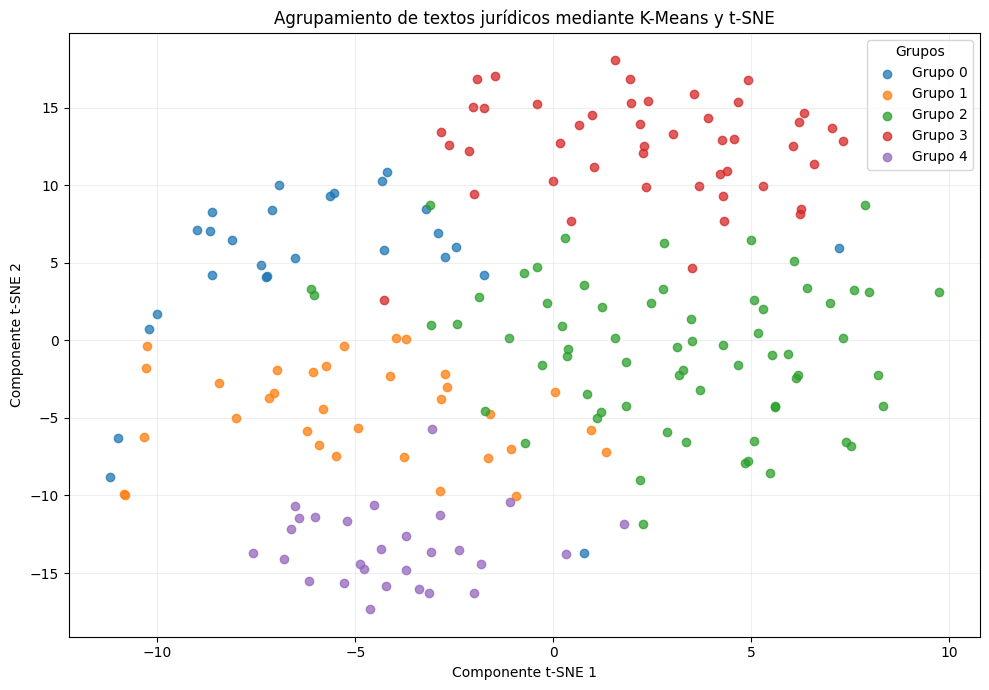

In [40]:

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Reducir los embeddings de 384 dimensiones a dos dimensiones.
# Esto permite visualizar las relaciones entre los textos en un gráfico.
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)

# Calcular las coordenadas de cada texto en el espacio bidimensional.
coordenadas = tsne.fit_transform(embeddings)

# Guardar las coordenadas para relacionarlas con los textos originales.
df_act4["tsne_x"] = coordenadas[:, 0]
df_act4["tsne_y"] = coordenadas[:, 1]

# Crear el gráfico y representar cada grupo con un color diferente.
plt.figure(figsize=(10, 7))

for grupo in sorted(df_act4["grupo"].unique()):
    # Seleccionar los textos que pertenecen al grupo actual.
    datos_grupo = df_act4[df_act4["grupo"] == grupo]

    # Dibujar los textos del grupo en sus respectivas coordenadas.
    plt.scatter(
        datos_grupo["tsne_x"],
        datos_grupo["tsne_y"],
        label=f"Grupo {grupo}",
        alpha=0.75
    )

# Añadir títulos y etiquetas para facilitar la interpretación del gráfico.
plt.title("Agrupamiento de textos jurídicos mediante K-Means y t-SNE")
plt.xlabel("Componente t-SNE 1")
plt.ylabel("Componente t-SNE 2")
plt.legend(title="Grupos")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


En el gráfico se observan cinco grupos con distribuciones diferentes:
- Grupo 0 (azul): presenta una concentración principalmente en la zona superior izquierda, aunque tiene algunos puntos alejados.
- Grupo 1 (naranja): se concentra sobre todo en la zona inferior izquierda.
- Grupo 2 (verde): tiene una distribución más amplia en la zona central y derecha, lo que sugiere mayor diversidad entre sus textos.
- Grupo 3 (rojo): aparece principalmente en la zona superior derecha y muestra una concentración relativamente clara.
- Grupo 4 (morado): se concentra en la zona inferior, con algunos puntos separados.